# pT spectrum: unbiased vs biased

Plots the output of `startBasis.C` (see `BIAS.md`): `tRef` (unbiased, X + Y) and `tBiased` (X downsampled + Y′).
Requires `uproot`, `numpy`, `matplotlib`. Run from `AnalysisCode/`; inputs are read from `../Output/files/`, plots saved to `../Output/plots/`.

In [1]:
import numpy as np
import uproot
import matplotlib.pyplot as plt

In [2]:
# --- EDIT ---
INPUT = "../Output/files/startBasis_100_140.root"   # written by driveBins.C
PLOT_DIR = "../Output/plots"
PT_MIN, PT_MAX = 100.0, 140.0
P, D = 8.0, 0.1
NBINS = 20

In [3]:
def w_bias(pt, lo, hi, p, d):
    """Probability to keep an X jet, as in startBasis.C."""
    pt = np.asarray(pt, dtype=float)
    return (lo**p - d * hi**p + (d - 1) * pt**p) / (lo**p - hi**p)

def hist(a, edges):
    """Weighted histogram and its statistical error."""
    h, _ = np.histogram(a["pt_raw"], bins=edges, weights=a["weight"])
    h2, _ = np.histogram(a["pt_raw"], bins=edges, weights=a["weight"] ** 2)
    return h, np.sqrt(h2)

In [4]:
with uproot.open(INPUT) as f:
    arr = {n: f[n].arrays(["pt_raw", "weight"], library="np") for n in ("tX", "tRef", "tBiased")}

edges = np.linspace(PT_MIN, PT_MAX, NBINS + 1)
ctr = 0.5 * (edges[1:] + edges[:-1])
h_ref, e_ref = hist(arr["tRef"], edges)
h_bia, e_bia = hist(arr["tBiased"], edges)

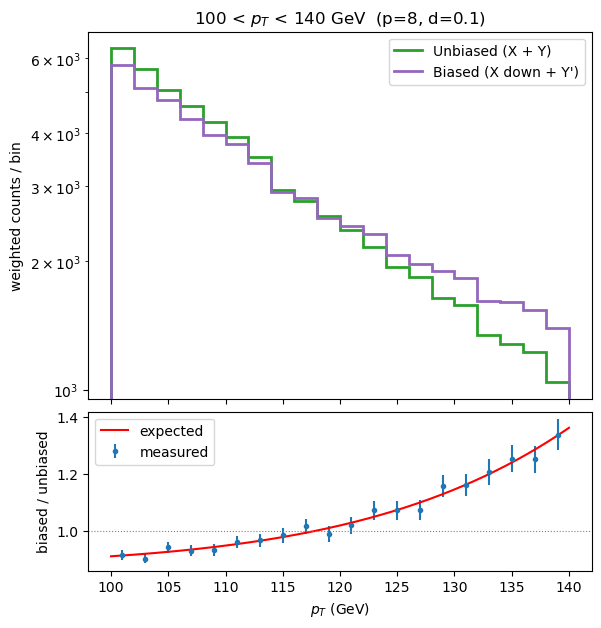

In [5]:
fig, (ax, axr) = plt.subplots(2, 1, figsize=(6.5, 7), sharex=True,
                              gridspec_kw={"height_ratios": [3, 1.3], "hspace": 0.05})
ax.stairs(h_ref, edges, color="tab:green", lw=2, label="Unbiased (X + Y)")
ax.stairs(h_bia, edges, color="tab:purple", lw=2, label="Biased (X down + Y')")
ax.set_yscale("log")
ax.set_ylabel("weighted counts / bin")
ax.set_title(f"{PT_MIN:g} < $p_T$ < {PT_MAX:g} GeV  (p={P:g}, d={D:g})")
ax.legend()

ok = h_ref > 0
ratio = np.full_like(h_ref, np.nan)
ratio[ok] = h_bia[ok] / h_ref[ok]
rerr = np.full_like(h_ref, np.nan)
g = ok & (h_bia > 0)
rerr[g] = ratio[g] * np.hypot(e_bia[g] / h_bia[g], e_ref[g] / h_ref[g])
axr.errorbar(ctr, ratio, rerr, fmt="o", ms=3, label="measured")

# expected ratio: (w_bias(pT) + 2 - k) / 2, k = <w_bias> over X jets
k = w_bias(arr["tX"]["pt_raw"], PT_MIN, PT_MAX, P, D).mean()
x = np.linspace(PT_MIN, PT_MAX, 300)
axr.plot(x, (w_bias(x, PT_MIN, PT_MAX, P, D) + 2 - k) / 2, "r-", label="expected")
axr.axhline(1, color="gray", ls=":", lw=0.8)
axr.set_xlabel("$p_T$ (GeV)")
axr.set_ylabel("biased / unbiased")
axr.legend()
plt.savefig(f"{PLOT_DIR}/plot_pt_bias_{PT_MIN:g}_{PT_MAX:g}.pdf", bbox_inches="tight")
plt.show()

## Log-normal bias

Output of `startBasis.C` run with `biasType=1` (see `BIAS.md`). The X keep probability is the log-normal $\bar D(p_T)$ divided by its peak value.

In [6]:
# --- EDIT (must match the startBasis run with biasType=1) ---
LN_INPUT = "../Output/files/startBasis_100_140_lognormal.root"   # written by driveBinsLognormal.C
LN_MU, LN_SIGMA = 4.733, 0.12
LN_NORM = 1.0   # amplitude of w (maximum keep probability); 1 = strongest bias

def lognormal_pdf(pt, mu, sigma):
    """Log-normal D(pt) = exp[-(ln pt - mu)^2 / (2 sigma^2)] / (sqrt(2 pi) sigma pt)."""
    pt = np.asarray(pt, dtype=float)
    return np.exp(-(np.log(pt) - mu) ** 2 / (2 * sigma**2)) / (np.sqrt(2 * np.pi) * sigma * pt)

def w_lognormal(pt, mu, sigma, norm=None):
    """Keep probability as in lognormalBiasWeight(): norm * D(pt) / D(mode), mode = exp(mu - sigma^2), capped at 1."""
    norm = LN_NORM if norm is None else norm
    w = norm * lognormal_pdf(pt, mu, sigma) / lognormal_pdf(np.exp(mu - sigma**2), mu, sigma)
    return np.minimum(w, 1.0)

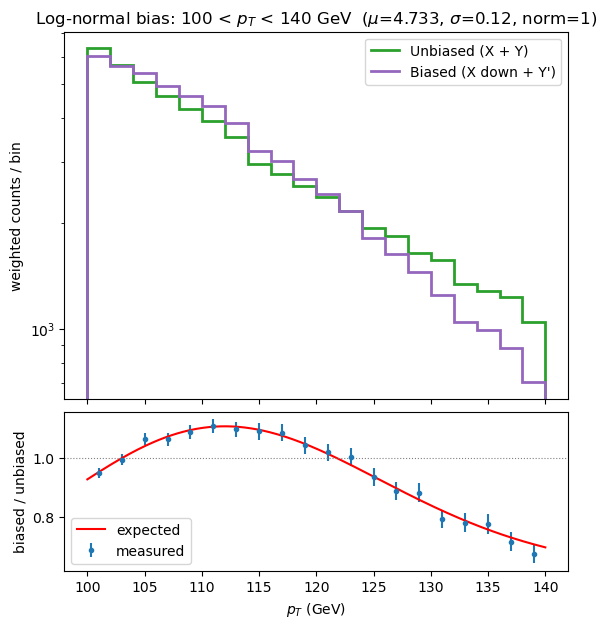

In [7]:
with uproot.open(LN_INPUT) as f:
    ln = {n: f[n].arrays(["pt_raw", "weight"], library="np") for n in ("tX", "tRef", "tBiased")}

lh_ref, le_ref = hist(ln["tRef"], edges)
lh_bia, le_bia = hist(ln["tBiased"], edges)
x = np.linspace(PT_MIN, PT_MAX, 300)

fig, (ax, axr) = plt.subplots(2, 1, figsize=(6.5, 7), sharex=True,
                              gridspec_kw={"height_ratios": [3, 1.3], "hspace": 0.05})
ax.stairs(lh_ref, edges, color="tab:green", lw=2, label="Unbiased (X + Y)")
ax.stairs(lh_bia, edges, color="tab:purple", lw=2, label="Biased (X down + Y')")
ax.set_yscale("log")
ax.set_ylabel("weighted counts / bin")
ax.set_title(f"Log-normal bias: {PT_MIN:g} < $p_T$ < {PT_MAX:g} GeV  ($\\mu$={LN_MU:g}, $\\sigma$={LN_SIGMA:g}, norm={LN_NORM:g})")
ax.legend()

ok = lh_ref > 0
ratio = np.full_like(lh_ref, np.nan)
ratio[ok] = lh_bia[ok] / lh_ref[ok]
rerr = np.full_like(lh_ref, np.nan)
g = ok & (lh_bia > 0)
rerr[g] = ratio[g] * np.hypot(le_bia[g] / lh_bia[g], le_ref[g] / lh_ref[g])
axr.errorbar(ctr, ratio, rerr, fmt="o", ms=3, label="measured")

# expected ratio: (w(pT) + 2 - k) / 2, k = <w> over X jets
k = w_lognormal(ln["tX"]["pt_raw"], LN_MU, LN_SIGMA).mean()
axr.plot(x, (w_lognormal(x, LN_MU, LN_SIGMA) + 2 - k) / 2, "r-", label="expected")
axr.axhline(1, color="gray", ls=":", lw=0.8)
axr.set_xlabel("$p_T$ (GeV)")
axr.set_ylabel("biased / unbiased")
axr.legend()
plt.savefig(f"{PLOT_DIR}/plot_pt_bias_{PT_MIN:g}_{PT_MAX:g}_lognormal.pdf", bbox_inches="tight")
plt.show()